# Flood forecasting with CNN-LSTM: data pre-processing and visualisation
**DL Lab project** · Anhad Mahajan & Aman Sumeet Saxena

This notebook covers everything that happens **before** the model:

1. **The dataset**: four simulated floods (Australia, UK, Pakistan, Mozambique)
2. **Pre-processing**: how the raw map files become lined-up arrays, with a live demo
3. **The four floods**: maps, how they grow, and rain against flooding
4. **Checks**: water balance, water depths, and how fast the floods change
5. **Model-ready data**: severity labels, train / validation / test split, normalisation, and one training example

Every figure and table is saved to Google Drive in `Flood_project/lab_outputs/`.
The labels, split and normalisation values for the model are saved in `Flood_project/model_inputs/`.

## 0. Setup
Needs the prepared data from the *Data_preparation* notebook in `Flood_project/prepared_data/` on Google Drive.
A normal CPU runtime is enough.

In [ ]:
# Install rasterio, the library that reads map files (.tif).
!pip install -q rasterio

In [ ]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
import rasterio
from rasterio.enums import Resampling
from rasterio.windows import Window
from huggingface_hub import hf_hub_download, HfApi
from google.colab import drive

In [ ]:
# Connect Google Drive
drive.mount("/content/drive")

# Folders used by this notebook
PROJECT_DIR = "/content/drive/MyDrive/Flood_project"
PREPARED_DIR = os.path.join(PROJECT_DIR, "prepared_data")
FIGURE_DIR = os.path.join(PROJECT_DIR, "lab_outputs", "figures")
TABLE_DIR = os.path.join(PROJECT_DIR, "lab_outputs", "tables")
MODEL_INPUT_DIR = os.path.join(PROJECT_DIR, "model_inputs")

# Create the output folders if they don't exist yet
os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(MODEL_INPUT_DIR, exist_ok=True)

print("Figures will be saved in:", FIGURE_DIR)
print("Tables will be saved in: ", TABLE_DIR)
print("Model inputs saved in:   ", MODEL_INPUT_DIR)

Mounted at /content/drive
Figures will be saved in: /content/drive/MyDrive/Flood_project/lab_outputs/figures
Tables will be saved in:  /content/drive/MyDrive/Flood_project/lab_outputs/tables
Model inputs saved in:    /content/drive/MyDrive/Flood_project/model_inputs


In [ ]:
# All six prepared datasets (two resolutions each for Australia and the UK)
ALL_DATASETS = [
    "Australia_30m",
    "UK_30m",
    "Australia_60m",
    "UK_60m",
    "Pakistan_480m",
    "Mozambique_480m",
]

# One dataset per region, used for the figures
MAIN_DATASETS = {
    "Australia_30m": "Australia (30 m)",
    "UK_30m": "UK (30 m)",
    "Pakistan_480m": "Pakistan (480 m)",
    "Mozambique_480m": "Mozambique (480 m)",
}

# Line colour for each region in the plots
REGION_COLOURS = {
    "Australia_30m": "tab:orange",
    "UK_30m": "tab:green",
    "Pakistan_480m": "tab:red",
    "Mozambique_480m": "tab:blue",
}

# Time between two prepared maps
STEP_HOURS = 0.5

# A cell counts as "wet" above 1 cm of water, and as "flooded" above 30 cm
WET_DEPTH_M = 0.01
FLOOD_DEPTH_M = 0.30

# Size of one square tile (cells) for the tile version of the model
TILE_SIZE = 128

# New severity label: share of a tile's normally-dry land under more than 30 cm of water
SEVERITY_LIMITS = [0.05, 0.15, 0.30]
SEVERITY_NAMES = ["None", "Minor", "Moderate", "Severe"]
SEVERITY_COLOURS = ["#c7e9c0", "#fdd49e", "#fc8d59", "#d7301f"]

# Old severity label: deepest single cell in the tile (0.3 m, 1 m and 2 m limits)
OLD_SEVERITY_DEPTHS = [0.3, 1.0, 2.0]

# Time split: first 70% of each flood for training, next 15% validation, last 15% test
TRAIN_SHARE = 0.70
VALIDATION_SHARE = 0.15

# One training example: 4 past maps (2 hours) in, 4 future maps (2 hours) out
INPUT_STEPS = 4
OUTPUT_STEPS = 4

# Name and colour of each land-cover code
LAND_COVER = {
    1:  ("Water",              "#1f78b4"),
    2:  ("Trees",              "#33a02c"),
    4:  ("Flooded vegetation", "#a6cee3"),
    5:  ("Crops",              "#fdbf6f"),
    7:  ("Buildings",          "#e31a1c"),
    8:  ("Bare ground",        "#b15928"),
    9:  ("Snow / ice",         "#ffffff"),
    10: ("Clouds",             "#bdbdbd"),
    11: ("Rangeland",          "#b2df8a"),
}

land_cover_colours = ListedColormap([colour for name, colour in LAND_COVER.values()])
land_cover_names = [name for name, colour in LAND_COVER.values()]

# Blue colour scale that starts at light blue, so shallow water stays visible.
# Dry cells are stored as missing values and shown in grey.
water_colours = ListedColormap(plt.cm.Blues(np.linspace(0.3, 1.0, 256)))
water_colours.set_bad("lightgrey")

In [ ]:
def save_figure(fig, name):
    """Saves a figure as a PNG file in the figures folder on Drive."""

    path = os.path.join(FIGURE_DIR, name + ".png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved figure:", name + ".png")


def save_table(table, name):
    """Saves a table as a CSV file in the tables folder on Drive."""

    path = os.path.join(TABLE_DIR, name + ".csv")
    table.to_csv(path, index=False)
    print("Saved table:", name + ".csv")


def load_dataset(dataset, into_memory=True):
    """Loads one prepared dataset from Drive.
    into_memory=False reads the big arrays from the file only when needed, which saves memory."""

    folder = os.path.join(PREPARED_DIR, dataset)

    if into_memory:
        mode = None
    else:
        mode = "r"

    data = {
        "depth": np.load(os.path.join(folder, "depth.npy"), mmap_mode=mode),
        "rain": np.load(os.path.join(folder, "rain.npy"), mmap_mode=mode),
        "terrain": np.load(os.path.join(folder, "terrain.npy")),
        "land_cover": np.load(os.path.join(folder, "land_cover.npy")),
        "permanent_water": np.load(os.path.join(folder, "permanent_water.npy")),
    }

    with open(os.path.join(folder, "map_info.json")) as file:
        data["info"] = json.load(file)

    return data


def land_cover_positions(land_cover):
    """Turns land-cover codes (1, 2, 4, ...) into positions (0, 1, 2, ...) so each gets its own colour."""

    positions = np.full(land_cover.shape, np.nan)

    for position, code in enumerate(LAND_COVER.keys()):
        positions[land_cover == code] = position

    return positions


def show_water(ax, depth_map, top_value=None):
    """Draws a water-depth map: dry cells in grey, water in blue."""

    water = np.array(depth_map, dtype="float32")
    water[water < WET_DEPTH_M] = np.nan

    if top_value is None:
        top_value = np.nanpercentile(water, 98)

    return ax.imshow(water, cmap=water_colours, vmin=0, vmax=top_value)


def cut_into_tiles(rows, columns):
    """Returns the position and size of every full 128 x 128 tile in a map.
    A map too small for one full tile is used whole, as a single tile."""

    tiles = []

    for top in range(0, rows - TILE_SIZE + 1, TILE_SIZE):
        for left in range(0, columns - TILE_SIZE + 1, TILE_SIZE):
            tiles.append((top, left, TILE_SIZE, TILE_SIZE))

    if len(tiles) == 0:
        tiles.append((0, 0, rows, columns))

    return tiles

In [ ]:
# Check that the prepared data is on Drive
missing = []

for dataset in ALL_DATASETS:
    if not os.path.exists(os.path.join(PREPARED_DIR, dataset, "depth.npy")):
        missing.append(dataset)

if len(missing) == 0:
    print("All prepared datasets found")
else:
    print("Missing:", missing, "-> run the Data_preparation notebook first")

All prepared datasets found


## 1. The dataset: FloodCastBench
FloodCastBench (Xu et al., *Scientific Data*, 2025) contains four real flood events, re-created with a physics
simulator that solves the 2D shallow-water equations. For each flood it provides:

- **water depth** maps every 5 minutes (the target we forecast)
- **rain** maps every 30 minutes (satellite rainfall, GPM-IMERG)
- **ground height** (DEM) and **land cover** maps

| Region | Event | Resolution in the dataset |
|---|---|---|
| Australia | 20 Feb – 2 Mar 2022 | 30 m and 60 m |
| UK | 4 – 7 Dec 2015 | 30 m and 60 m |
| Pakistan | 18 – 31 Aug 2022 | 480 m |
| Mozambique | 14 – 20 Mar 2019 | 480 m |

We keep one depth map every **30 minutes**, the same spacing as the rain.

In [ ]:
# Load the four main datasets into memory (takes a few minutes: Australia 30 m alone is about 3 GB)
data = {}

for dataset in MAIN_DATASETS:
    data[dataset] = load_dataset(dataset)
    print(dataset, "- loaded", data[dataset]["depth"].shape[0], "maps of",
          data[dataset]["depth"].shape[1], "x", data[dataset]["depth"].shape[2])

Australia_30m - loaded 481 maps of 1073 x 1073
UK_30m - loaded 145 maps of 170 x 275
Pakistan_480m - loaded 673 maps of 810 x 441
Mozambique_480m - loaded 289 maps of 151 x 138


In [ ]:
# Overview of all six datasets
overview_rows = []

for dataset in ALL_DATASETS:
    saved = load_dataset(dataset, into_memory=False)
    info = saved["info"]
    depth = saved["depth"]

    # Go through the flood one map at a time: deepest water, and largest share of the map under 30 cm or more
    deepest = 0.0
    largest_flooded_share = 0.0

    for step in range(depth.shape[0]):
        deepest = max(deepest, float(np.max(depth[step])))
        largest_flooded_share = max(largest_flooded_share, float(np.mean(depth[step] > FLOOD_DEPTH_M)))

    area_km2 = info["rows"] * info["columns"] * info["resolution_m"] ** 2 / 1e6

    overview_rows.append({
        "Dataset": dataset,
        "Cell size (m)": info["resolution_m"],
        "Map size (rows x columns)": str(info["rows"]) + " x " + str(info["columns"]),
        "Area (km²)": round(area_km2, 1),
        "Maps (every 30 min)": info["number_of_maps"],
        "Hours covered": (info["number_of_maps"] - 1) * STEP_HOURS,
        "Deepest water (m)": round(deepest, 2),
        "Largest share under 30 cm+ of water (%)": round(100 * largest_flooded_share, 1),
    })

overview_table = pd.DataFrame(overview_rows)
display(overview_table)
save_table(overview_table, "01_dataset_overview")

,Dataset,Cell size (m),Map size (rows x columns),Area (km²),Maps (every 30 min),Hours covered,Deepest water (m),Largest share under 30 cm+ of water (%)
0,Australia_30m,30,1073 x 1073,1036.2,481,240.0,19.21,39.3
1,UK_30m,30,170 x 275,42.1,145,72.0,6.11,12.0
2,Australia_60m,60,536 x 536,1034.3,481,240.0,15.01,40.8
3,UK_60m,60,85 x 137,41.9,145,72.0,4.88,12.8
4,Pakistan_480m,480,810 x 441,82301.2,673,336.0,26.67,38.7
5,Mozambique_480m,480,151 x 138,4801.1,289,144.0,12.41,20.7


Saved table: 01_dataset_overview.csv


## 2. Pre-processing
Done once in the *Data_preparation* notebook; the results are stored on Drive.

| Step | What we do | Why |
|---|---|---|
| 1. Keep one depth map every 30 min | 1 of every 6 depth files | Rain is recorded every 30 min; over 5 min the water barely changes |
| 2. Put every layer on the depth map's grid | Ground height and rain: average of the 30 m cells inside each depth cell. Land cover: most common class | Every input must describe exactly the same place |
| 3. Check the alignment | Rivers (land cover) and valleys (ground height) compared with where water collects | A shifted layer would silently give the model wrong inputs |
| 4. Store rain honestly | `rain[t]` = rain falling **between** map t and map t+1 | The model may only use rain that has already fallen |
| 5. Save to Google Drive | One `.npy` array per layer | Loads in seconds instead of downloading 27 GB again |

How rain lines up with the depth maps:

    depth map 0         depth map 1         depth map 2
         |----- rain[0] -----|----- rain[1] -----|
       0 min              30 min              60 min

To forecast map 2 at time "map 1", the model may use `rain[0]` (already fallen) but **not** `rain[1]`.

### 2a. Live demo: pre-processing one dataset (UK, 60 m)
The raw ground-height and rain files are on a **30 m grid** that is slightly larger than the flood map.
The flood map covers the red box. Every **2 x 2** block of 30 m cells inside the box becomes **one 60 m cell**.
The demo downloads 3 small raw files, repeats the pre-processing, and checks the result against the saved data.

In [ ]:
RUN_LIVE_DEMO = True

REPO_ID = "mahajananhad/floodcastbench"
RAW_DIR = "/content/raw_demo"

# Where the UK 60 m flood map sits on the 30 m grid: 2 x 2 cells per flood cell, top-left corner at row 5, column 5
DEMO_SCALE = 2
DEMO_ROW_OFFSET = 5
DEMO_COL_OFFSET = 5

# Which rain map to show (step 47 = 23.5 hours in, during heavy rain)
DEMO_RAIN_STEP = 47

# Load the Hugging Face token from Colab's secrets, if there is one
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = None

try:
    # Find the name of the chosen UK rain file
    all_files = HfApi().list_repo_files(REPO_ID, repo_type="dataset", token=HF_TOKEN)
    uk_rain_files = sorted([f for f in all_files if f.startswith("Relevant data/Rainfall/UK flood/")])

    demo_files = {
        "ground_height": "Relevant data/DEM/UK_DEM.tif",
        "land_cover": "Relevant data/Land use and land cover/UK.tif",
        "rain": uk_rain_files[DEMO_RAIN_STEP],
    }

    # Download the three raw files
    demo_paths = {}

    for name, file_name in demo_files.items():
        demo_paths[name] = hf_hub_download(REPO_ID, file_name, repo_type="dataset", token=HF_TOKEN, local_dir=RAW_DIR)

    print("Raw files downloaded:", list(demo_files.values()))

except Exception as error:
    RUN_LIVE_DEMO = False
    print("Live demo skipped (download failed):", error)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Relevant data/DEM/UK_DEM.tif: reconstructing file:   0%|          |  0.00B /  394kB            

Relevant data/DEM/UK_DEM.tif: downloading bytes:           |  0.00B            

UK.tif:   0%|          | 0.00/7.64k [00:00<?, ?B/s]

20151205-S113000.tif:   0%|          | 0.00/8.81k [00:00<?, ?B/s]

Raw files downloaded: ['Relevant data/DEM/UK_DEM.tif', 'Relevant data/Land use and land cover/UK.tif', 'Relevant data/Rainfall/UK flood/20151205-S113000.tif']


In [ ]:
def read_raw_map(file_path):
    """Reads a whole raw 30 m map. The huge negative 'no data' values become missing values."""

    with rasterio.open(file_path) as source:
        data = source.read(1).astype("float32")

    data[data < -1e30] = np.nan

    return data


def read_on_depth_grid(file_path, scale, row_offset, col_offset, rows, columns, method):
    """The core pre-processing step: cut out the part of a 30 m map that lies under the flood map,
    and shrink it onto the flood map's grid (average for numbers, most common class for land cover)."""

    # The area of the 30 m map that the flood map covers
    window = Window(col_off=col_offset, row_off=row_offset, width=columns * scale, height=rows * scale)

    with rasterio.open(file_path) as source:
        data = source.read(1, window=window, out_shape=(rows, columns), resampling=method)

    return data.astype("float32")

,Layer,Matches the saved data
0,Ground height,True
1,Rain,True
2,Land cover,True


Saved figure: 02_preprocessing_demo_UK.png


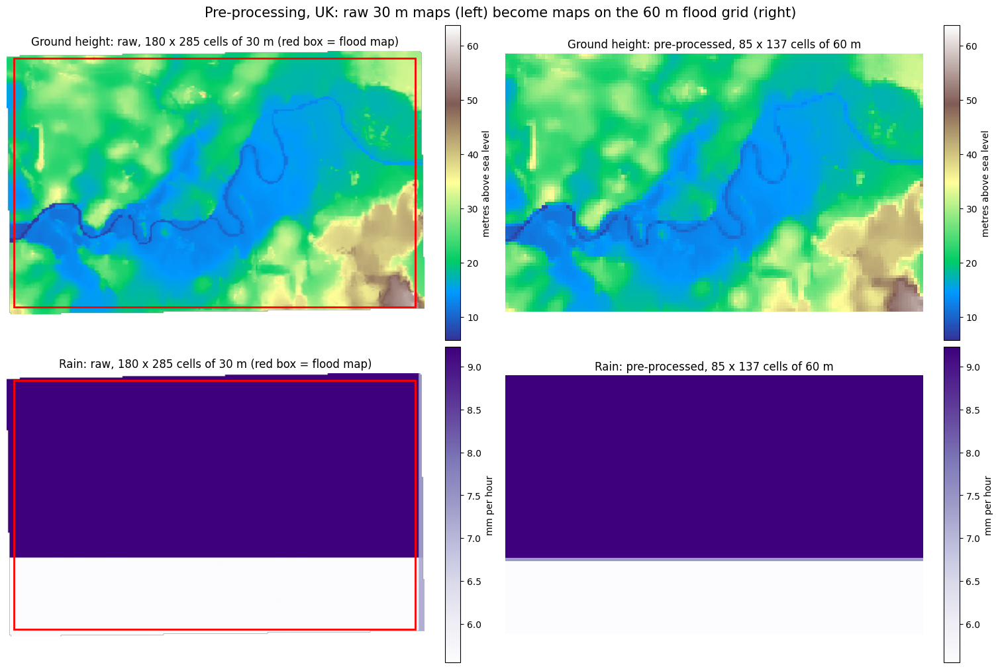

In [ ]:
if RUN_LIVE_DEMO:

    # The saved UK 60 m data, to compare against
    saved_uk = load_dataset("UK_60m")
    rows, columns = saved_uk["terrain"].shape

    # Repeat the pre-processing on the raw files
    new_ground = read_on_depth_grid(demo_paths["ground_height"], DEMO_SCALE, DEMO_ROW_OFFSET, DEMO_COL_OFFSET,
                                    rows, columns, Resampling.average)
    new_rain = read_on_depth_grid(demo_paths["rain"], DEMO_SCALE, DEMO_ROW_OFFSET, DEMO_COL_OFFSET,
                                  rows, columns, Resampling.average)
    new_land_cover = read_on_depth_grid(demo_paths["land_cover"], DEMO_SCALE, DEMO_ROW_OFFSET, DEMO_COL_OFFSET,
                                        rows, columns, Resampling.mode)

    # Does the result match what was saved on Drive?
    saved_rain = np.array(saved_uk["rain"][DEMO_RAIN_STEP], dtype="float32")

    demo_check = pd.DataFrame([
        {"Layer": "Ground height", "Matches the saved data": bool(np.allclose(new_ground, saved_uk["terrain"], atol=0.01))},
        {"Layer": "Rain", "Matches the saved data": bool(np.allclose(new_rain, saved_rain, atol=0.05))},
        {"Layer": "Land cover", "Matches the saved data": bool(np.array_equal(new_land_cover, saved_uk["land_cover"]))},
    ])
    display(demo_check)

    # Pictures: raw 30 m maps with the flood-map area in red, next to the pre-processed 60 m maps
    raw_ground = read_raw_map(demo_paths["ground_height"])
    raw_rain = read_raw_map(demo_paths["rain"])

    fig, axes = plt.subplots(2, 2, figsize=(15, 10), layout="constrained")
    fig.suptitle("Pre-processing, UK: raw 30 m maps (left) become maps on the 60 m flood grid (right)", fontsize=15)

    pairs = [
        (raw_ground, new_ground, "Ground height", "terrain", "metres above sea level"),
        (raw_rain, new_rain, "Rain", "Purples", "mm per hour"),
    ]

    for row, (raw_map, new_map, name, colours, unit) in enumerate(pairs):

        # Same colour range for the raw and the pre-processed picture
        low = np.nanmin(raw_map)
        high = np.nanmax(raw_map)

        picture = axes[row, 0].imshow(raw_map, cmap=colours, vmin=low, vmax=high)
        axes[row, 0].add_patch(Rectangle((DEMO_COL_OFFSET - 0.5, DEMO_ROW_OFFSET - 0.5),
                                         columns * DEMO_SCALE, rows * DEMO_SCALE,
                                         fill=False, edgecolor="red", linewidth=2))
        axes[row, 0].set_title(name + ": raw, " + str(raw_map.shape[0]) + " x " + str(raw_map.shape[1]) +
                               " cells of 30 m (red box = flood map)")
        fig.colorbar(picture, ax=axes[row, 0], label=unit)

        picture = axes[row, 1].imshow(new_map, cmap=colours, vmin=low, vmax=high)
        axes[row, 1].set_title(name + ": pre-processed, " + str(rows) + " x " + str(columns) + " cells of 60 m")
        fig.colorbar(picture, ax=axes[row, 1], label=unit)

    for ax in axes.flat:
        ax.axis("off")

    save_figure(fig, "02_preprocessing_demo_UK")
    plt.show()

## 3. The four floods

In [ ]:
# For every region, measure the whole map at every 30-minute step
timeline = {}

for dataset in MAIN_DATASETS:
    depth = data[dataset]["depth"]
    rain = data[dataset]["rain"]

    # Share of the map under more than 30 cm of water
    flooded_share = np.mean(depth > FLOOD_DEPTH_M, axis=(1, 2))

    # Average water depth over the whole map (metres)
    average_depth = np.mean(depth, axis=(1, 2))

    # Average rain over the whole map (mm per hour)
    average_rain = np.mean(rain, axis=(1, 2), dtype="float64")

    timeline[dataset] = {
        "hours": np.arange(depth.shape[0]) * STEP_HOURS,
        "flooded_share": flooded_share,
        "average_depth": average_depth,
        "average_rain": average_rain,
        "peak_step": int(np.argmax(flooded_share)),
    }

    print(dataset, "- largest flooding after", timeline[dataset]["peak_step"] * STEP_HOURS, "hours")

Australia_30m - largest flooding after 181.0 hours
UK_30m - largest flooding after 41.0 hours
Pakistan_480m - largest flooding after 179.5 hours
Mozambique_480m - largest flooding after 108.0 hours


Saved figure: 03_four_floods_overview.png


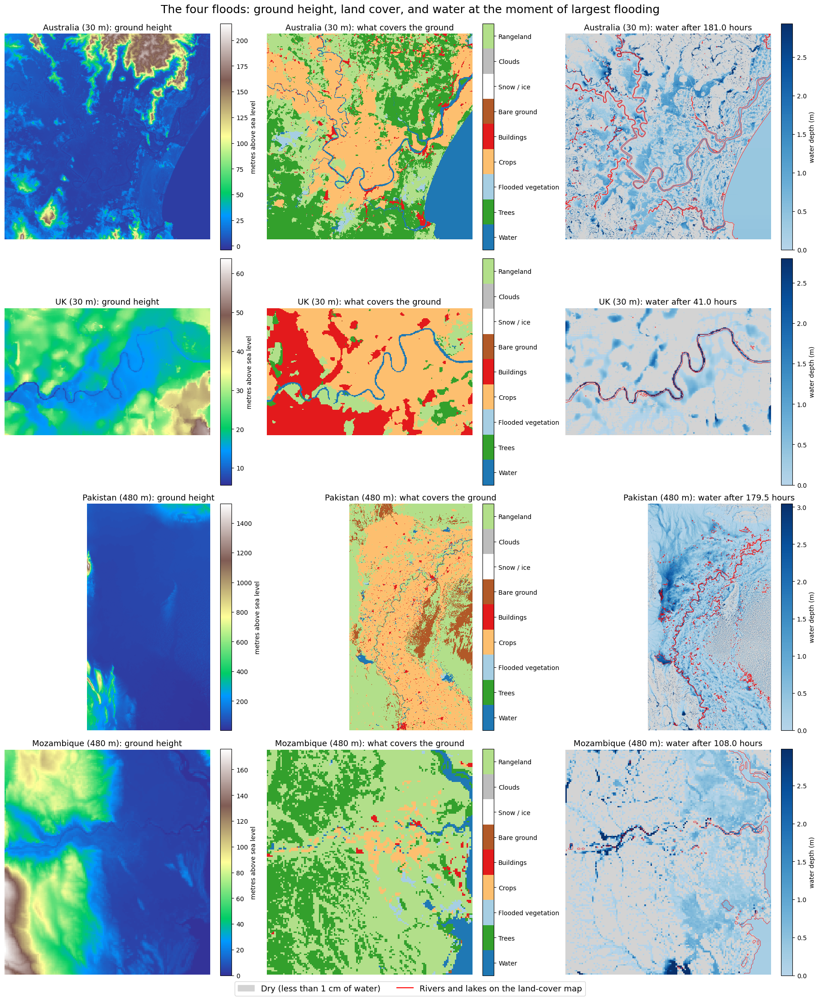

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(18, 22), layout="constrained")
fig.suptitle("The four floods: ground height, land cover, and water at the moment of largest flooding", fontsize=18)

for row, (dataset, title) in enumerate(MAIN_DATASETS.items()):
    region = data[dataset]
    peak = timeline[dataset]["peak_step"]

    # Ground height
    picture = axes[row, 0].imshow(region["terrain"], cmap="terrain")
    axes[row, 0].set_title(title + ": ground height", fontsize=13)
    fig.colorbar(picture, ax=axes[row, 0], label="metres above sea level")

    # Land cover
    picture = axes[row, 1].imshow(land_cover_positions(region["land_cover"]), cmap=land_cover_colours,
                                  vmin=-0.5, vmax=len(LAND_COVER) - 0.5, interpolation="nearest")
    axes[row, 1].set_title(title + ": what covers the ground", fontsize=13)
    colour_bar = fig.colorbar(picture, ax=axes[row, 1], ticks=range(len(LAND_COVER)))
    colour_bar.ax.set_yticklabels(land_cover_names)

    # Water at the moment of largest flooding, with rivers and lakes outlined in red
    picture = show_water(axes[row, 2], region["depth"][peak])
    axes[row, 2].contour(region["permanent_water"].astype(float), levels=[0.5], colors="red", linewidths=0.5)
    axes[row, 2].set_title(title + ": water after " + str(peak * STEP_HOURS) + " hours", fontsize=13)
    fig.colorbar(picture, ax=axes[row, 2], label="water depth (m)")

for ax in axes.flat:
    ax.axis("off")

legend_items = [
    Patch(color="lightgrey", label="Dry (less than 1 cm of water)"),
    Line2D([], [], color="red", label="Rivers and lakes on the land-cover map"),
]
fig.legend(handles=legend_items, loc="outside lower center", ncol=2, fontsize=13)

save_figure(fig, "03_four_floods_overview")
plt.show()

Saved figure: 04_flood_development.png


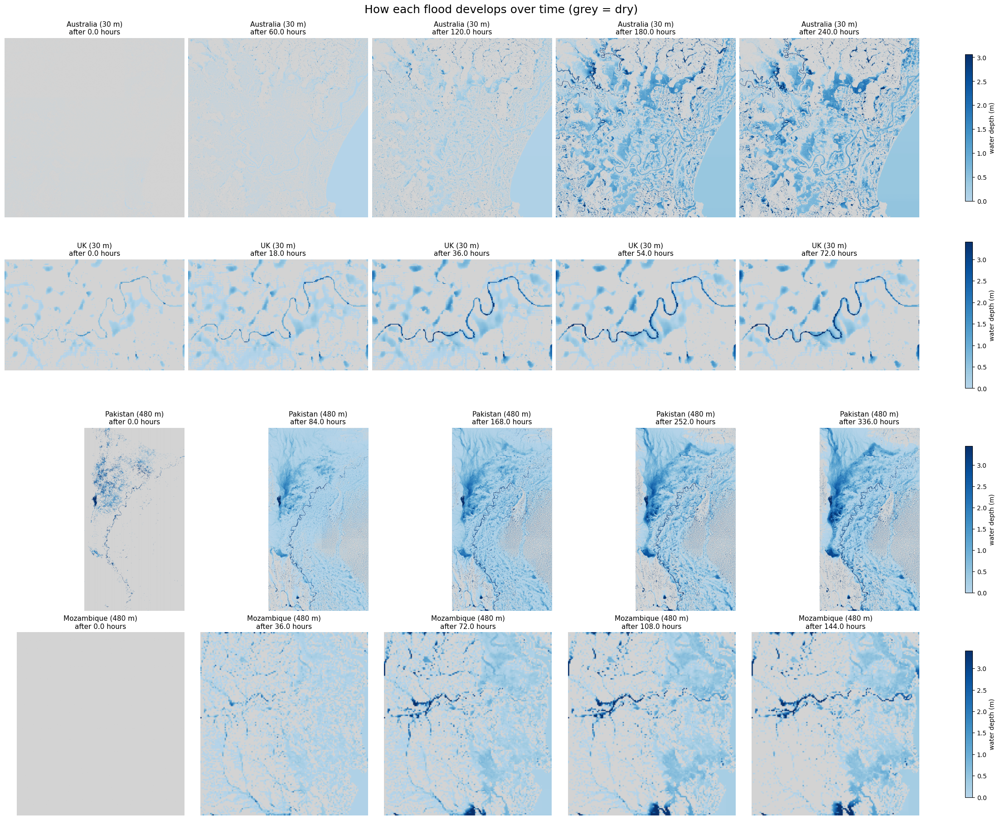

In [ ]:
# How each flood develops: five moments from the start to the end of the event
moments = [0.0, 0.25, 0.5, 0.75, 1.0]

fig, axes = plt.subplots(4, 5, figsize=(22, 18), layout="constrained")
fig.suptitle("How each flood develops over time (grey = dry)", fontsize=18)

for row, (dataset, title) in enumerate(MAIN_DATASETS.items()):
    depth = data[dataset]["depth"]
    last_step = depth.shape[0] - 1

    # One colour scale per region, taken from the last map
    last_map = depth[last_step]
    top_value = np.percentile(last_map[last_map > WET_DEPTH_M], 98)

    for column, moment in enumerate(moments):
        step = int(round(moment * last_step))

        picture = show_water(axes[row, column], depth[step], top_value)
        axes[row, column].set_title(title + "\nafter " + str(step * STEP_HOURS) + " hours", fontsize=11)
        axes[row, column].axis("off")

    fig.colorbar(picture, ax=axes[row, :], label="water depth (m)", shrink=0.8)

save_figure(fig, "04_flood_development")
plt.show()

Saved figure: 05_rain_and_flooded_area.png


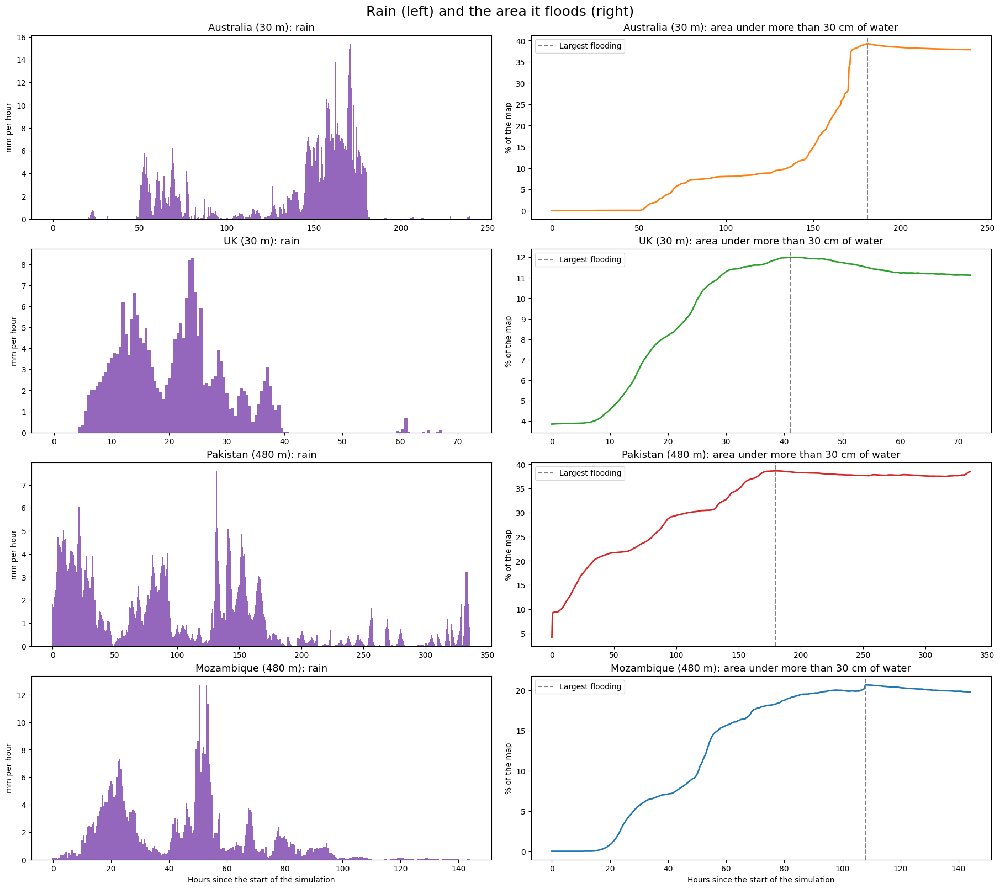

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(18, 16), layout="constrained")
fig.suptitle("Rain (left) and the area it floods (right)", fontsize=18)

for row, (dataset, title) in enumerate(MAIN_DATASETS.items()):
    t = timeline[dataset]
    peak_hour = t["peak_step"] * STEP_HOURS

    # Left: average rain over the map
    axes[row, 0].bar(t["hours"], t["average_rain"], width=STEP_HOURS, color="tab:purple")
    axes[row, 0].set_title(title + ": rain", fontsize=13)
    axes[row, 0].set_ylabel("mm per hour")

    # Right: share of the map under more than 30 cm of water
    axes[row, 1].plot(t["hours"], 100 * t["flooded_share"], color=REGION_COLOURS[dataset], linewidth=2)
    axes[row, 1].axvline(peak_hour, color="grey", linestyle="--", label="Largest flooding")
    axes[row, 1].set_title(title + ": area under more than 30 cm of water", fontsize=13)
    axes[row, 1].set_ylabel("% of the map")
    axes[row, 1].legend(loc="upper left")

axes[3, 0].set_xlabel("Hours since the start of the simulation")
axes[3, 1].set_xlabel("Hours since the start of the simulation")

save_figure(fig, "05_rain_and_flooded_area")
plt.show()

## 4. Checks
### 4a. Water balance
Physics (conservation of mass): if no water soaks in or leaves the area, then half an hour of rain at R mm per hour
adds **0.5 x R mm** of water to the map. The dashed line shows this. Each dot is one half hour of the flood.

Saved figure: 06_water_balance.png


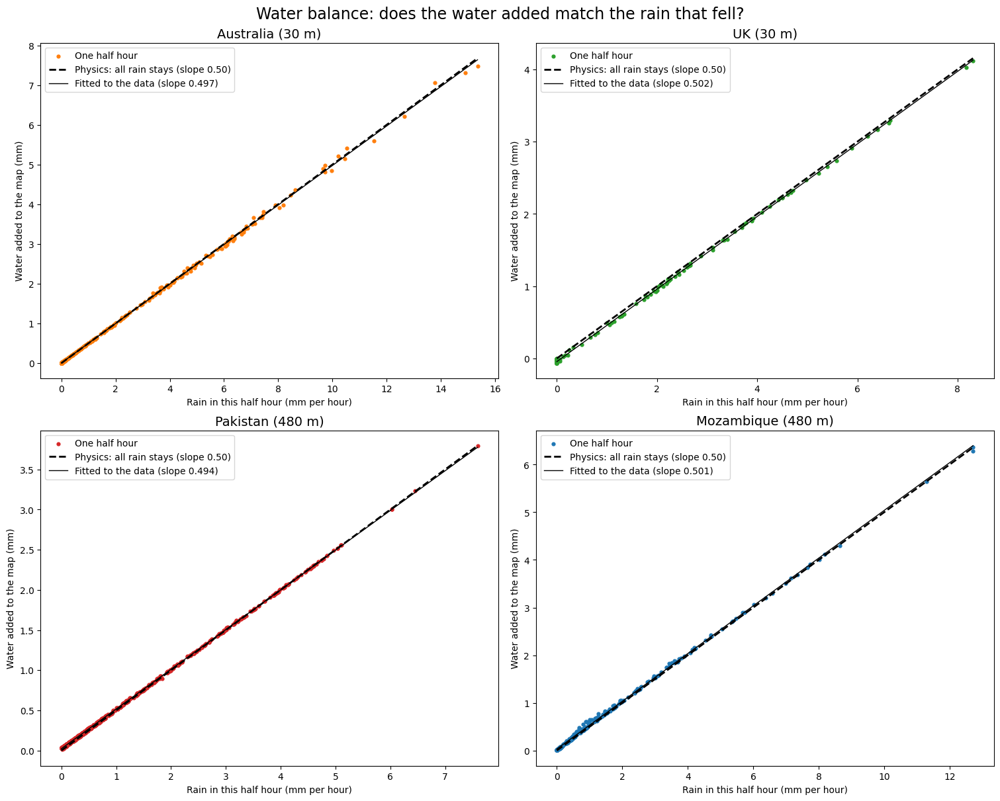

,Region,Fitted slope,Physics
0,Australia (30 m),0.497,0.5
1,UK (30 m),0.502,0.5
2,Pakistan (480 m),0.494,0.5
3,Mozambique (480 m),0.501,0.5


Saved table: 06_water_balance.csv


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12), layout="constrained")
fig.suptitle("Water balance: does the water added match the rain that fell?", fontsize=17)

balance_rows = []

for ax, (dataset, title) in zip(axes.flat, MAIN_DATASETS.items()):
    t = timeline[dataset]

    # Water added to the map in each half hour (mm), paired with the rain of that half hour
    water_added = np.diff(t["average_depth"]) * 1000
    rain_this_half_hour = t["average_rain"][:-1]

    # Best straight line through the dots
    slope, intercept = np.polyfit(rain_this_half_hour, water_added, 1)

    rain_range = np.linspace(0, rain_this_half_hour.max(), 50)

    ax.scatter(rain_this_half_hour, water_added, s=12, color=REGION_COLOURS[dataset], label="One half hour")
    ax.plot(rain_range, 0.5 * rain_range, "k--", linewidth=2, label="Physics: all rain stays (slope 0.50)")
    ax.plot(rain_range, slope * rain_range + intercept, color="black", linewidth=1,
            label="Fitted to the data (slope " + str(round(slope, 3)) + ")")

    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Rain in this half hour (mm per hour)")
    ax.set_ylabel("Water added to the map (mm)")
    ax.legend()

    balance_rows.append({"Region": title, "Fitted slope": round(slope, 3), "Physics": 0.5})

save_figure(fig, "06_water_balance")
plt.show()

balance_table = pd.DataFrame(balance_rows)
display(balance_table)
save_table(balance_table, "06_water_balance")

### 4b. How deep is the water?

Saved figure: 07_depth_distribution.png


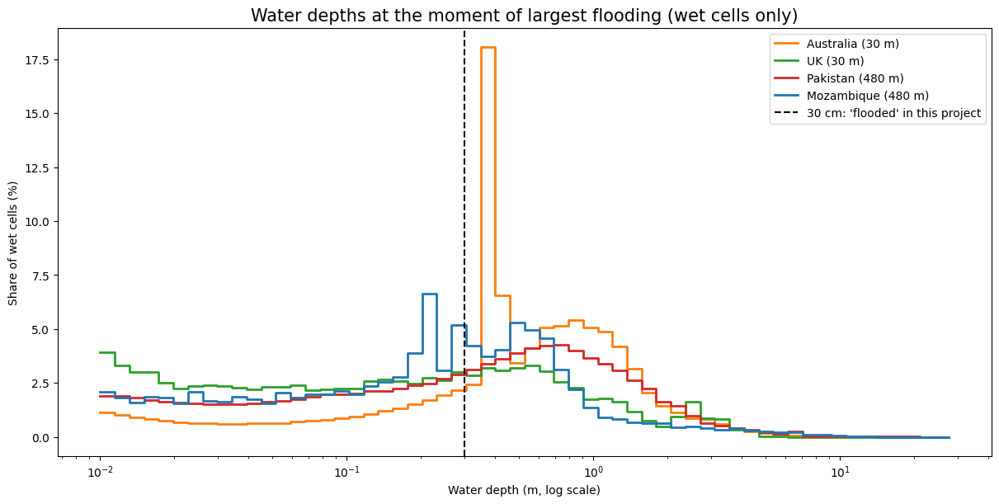

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")

# Depth classes on a log scale, from 1 cm to about 30 m
bins = np.logspace(np.log10(WET_DEPTH_M), 1.5, 60)

for dataset, title in MAIN_DATASETS.items():
    peak_map = data[dataset]["depth"][timeline[dataset]["peak_step"]]
    wet_depths = peak_map[peak_map >= WET_DEPTH_M]

    counts, edges = np.histogram(wet_depths, bins=bins)
    share = 100 * counts / counts.sum()

    ax.step(edges[:-1], share, where="post", color=REGION_COLOURS[dataset], linewidth=2, label=title)

ax.axvline(FLOOD_DEPTH_M, color="black", linestyle="--", label="30 cm: 'flooded' in this project")
ax.set_xscale("log")
ax.set_xlabel("Water depth (m, log scale)")
ax.set_ylabel("Share of wet cells (%)")
ax.set_title("Water depths at the moment of largest flooding (wet cells only)", fontsize=15)
ax.legend()

save_figure(fig, "07_depth_distribution")
plt.show()

### 4c. How fast do the floods change?
The simplest possible forecast is **"the water stays as it is"** (copy the last map), called *persistence*.
Its error shows how much actually changes over time. Our model must beat this curve,
and the further ahead we forecast, the more room there is to beat it.

Saved figure: 08_persistence_error.png


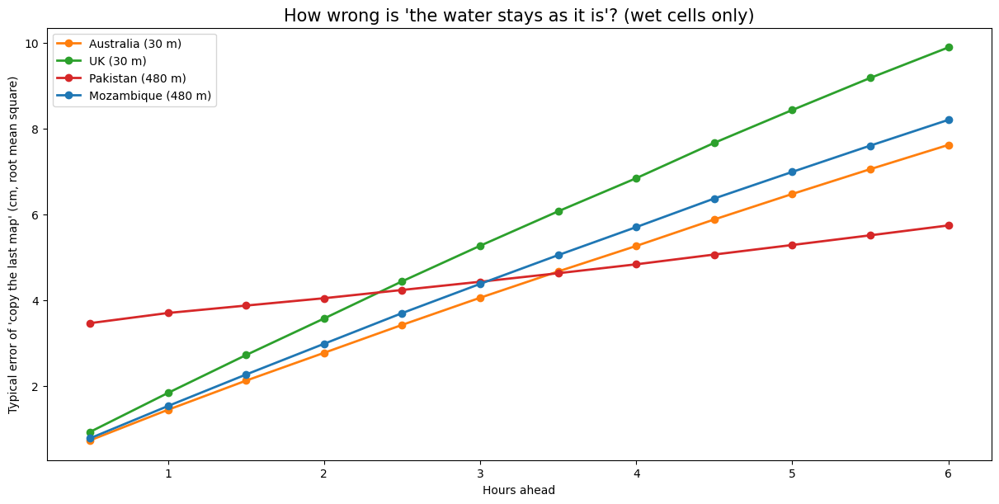

Saved table: 08_persistence_error.csv


In [ ]:
hours_ahead = np.arange(1, 13) * STEP_HOURS

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
persistence_rows = []

for dataset, title in MAIN_DATASETS.items():
    depth = data[dataset]["depth"]
    errors_cm = []

    for lead in range(1, 13):
        squared_error_sum = 0.0
        cell_count = 0

        # Every 4th starting time is enough to measure the typical error
        for start in range(0, depth.shape[0] - lead, 4):
            now = depth[start]
            later = depth[start + lead]

            # Only cells that are wet at either moment
            wet = (now > WET_DEPTH_M) | (later > WET_DEPTH_M)
            difference = (later[wet] - now[wet]).astype("float64")

            squared_error_sum += float(np.sum(difference ** 2))
            cell_count += int(wet.sum())

        errors_cm.append(100 * np.sqrt(squared_error_sum / cell_count))

    ax.plot(hours_ahead, errors_cm, marker="o", color=REGION_COLOURS[dataset], linewidth=2, label=title)

    for hours, error in zip(hours_ahead, errors_cm):
        persistence_rows.append({"Region": title, "Hours ahead": hours, "Persistence error (cm)": round(error, 2)})

ax.set_xlabel("Hours ahead")
ax.set_ylabel("Typical error of 'copy the last map' (cm, root mean square)")
ax.set_title("How wrong is 'the water stays as it is'? (wet cells only)", fontsize=15)
ax.legend()

save_figure(fig, "08_persistence_error")
plt.show()

save_table(pd.DataFrame(persistence_rows), "08_persistence_error")

## 5. Model-ready data
### 5a. New severity label (for the capsule network)
The model sees the flood in **128 x 128 tiles**. Each tile at each moment gets a severity class from the
**share of its normally-dry land that is under more than 30 cm of water** (rivers and lakes are left out):

| Class | Share of dry land flooded |
|---|---|
| None | less than 5% |
| Minor | 5% to 15% |
| Moderate | 15% to 30% |
| Severe | 30% or more |

The old label used only the **deepest single cell** in the tile, so one river channel made almost every tile "severe".

In [ ]:
severity = {}

for dataset in MAIN_DATASETS:
    depth = data[dataset]["depth"]
    dry_land = ~data[dataset]["permanent_water"]

    tiles = cut_into_tiles(depth.shape[1], depth.shape[2])
    number_of_maps = depth.shape[0]

    new_share = np.zeros((len(tiles), number_of_maps))
    old_label = np.zeros((len(tiles), number_of_maps), dtype=int)

    for number, (top, left, height, width) in enumerate(tiles):
        tile_depth = depth[:, top:top + height, left:left + width]
        tile_land = dry_land[top:top + height, left:left + width]

        # New label: share of the tile's normally-dry land under more than 30 cm of water
        flooded_land = (tile_depth > FLOOD_DEPTH_M) & tile_land
        new_share[number] = flooded_land.sum(axis=(1, 2)) / max(tile_land.sum(), 1)

        # Old label: only the deepest single cell in the tile
        deepest_cell = tile_depth.max(axis=(1, 2))
        old_label[number] = np.digitize(deepest_cell, OLD_SEVERITY_DEPTHS)

    new_label = np.digitize(new_share, SEVERITY_LIMITS)

    severity[dataset] = {"share": new_share, "new_label": new_label, "old_label": old_label}

    # Save the labels for the model
    np.savez(os.path.join(MODEL_INPUT_DIR, "severity_" + dataset + ".npz"),
             tiles=np.array(tiles), flooded_land_share=new_share, label=new_label)

    print(dataset, "-", len(tiles), "tiles x", number_of_maps, "moments =", new_label.size, "labelled examples")

Australia_30m - 64 tiles x 481 moments = 30784 labelled examples
UK_30m - 2 tiles x 145 moments = 290 labelled examples
Pakistan_480m - 18 tiles x 673 moments = 12114 labelled examples
Mozambique_480m - 1 tiles x 289 moments = 289 labelled examples


Saved figure: 09_severity_new_label.png


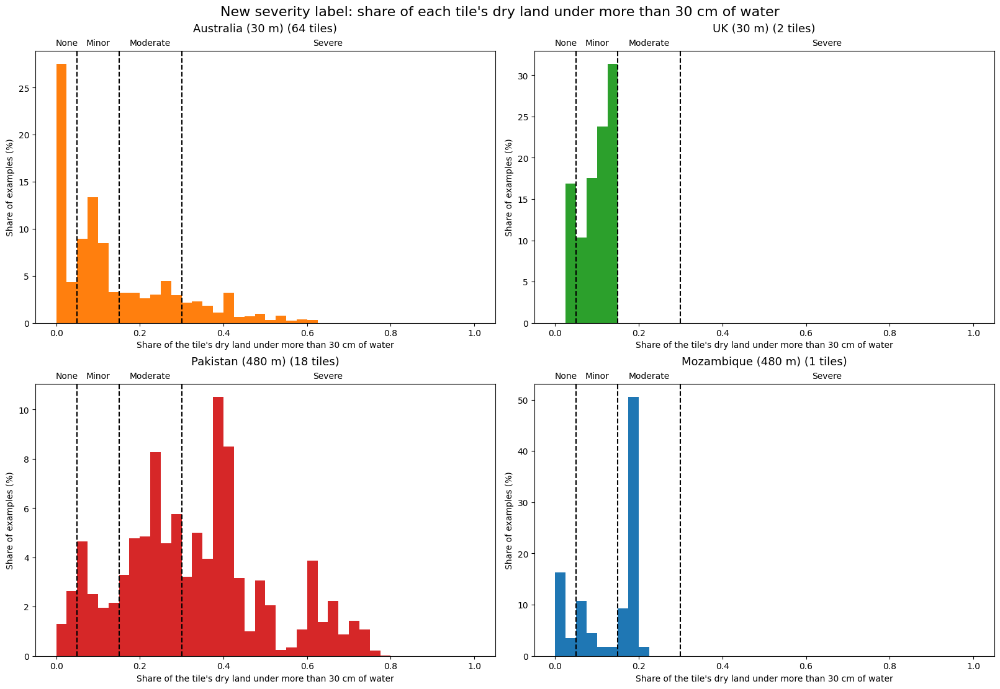

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11), layout="constrained")
fig.suptitle("New severity label: share of each tile's dry land under more than 30 cm of water", fontsize=16)

class_middles = [0.025, 0.10, 0.225, 0.65]

for ax, (dataset, title) in zip(axes.flat, MAIN_DATASETS.items()):
    shares = severity[dataset]["share"].ravel()

    ax.hist(shares, bins=np.linspace(0, 1, 41), weights=np.full(shares.size, 100 / shares.size),
            color=REGION_COLOURS[dataset])

    # Class limits and class names
    for limit in SEVERITY_LIMITS:
        ax.axvline(limit, color="black", linestyle="--")

    for middle, name in zip(class_middles, SEVERITY_NAMES):
        ax.text(middle, 1.02, name, transform=ax.get_xaxis_transform(), ha="center", fontsize=10)

    ax.set_title(title + " (" + str(severity[dataset]["share"].shape[0]) + " tiles)", fontsize=13, pad=22)
    ax.set_xlabel("Share of the tile's dry land under more than 30 cm of water")
    ax.set_ylabel("Share of examples (%)")

save_figure(fig, "09_severity_new_label")
plt.show()

Saved figure: 10_severity_old_vs_new.png


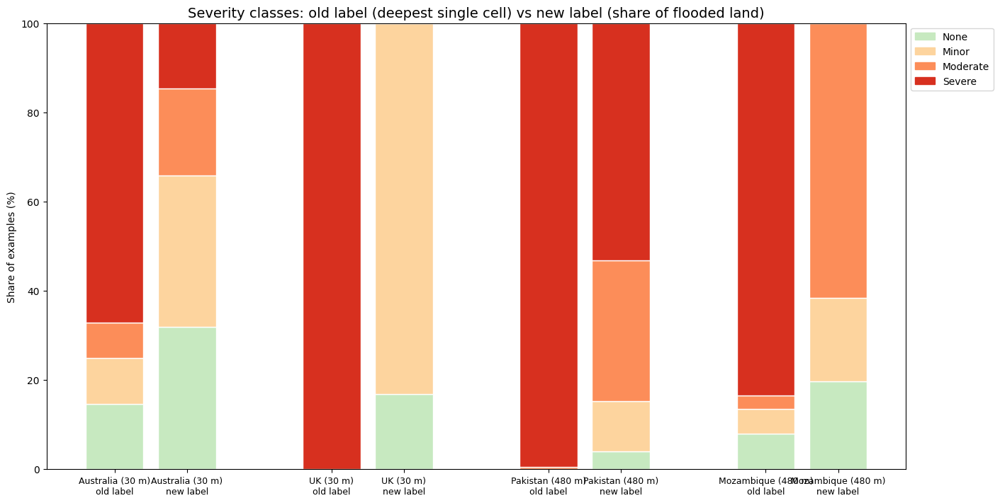

Saved table: 10_severity_classes.csv


In [ ]:
fig, ax = plt.subplots(figsize=(14, 7), layout="constrained")

bar_positions = []
bar_names = []
class_rows = []

for number, (dataset, title) in enumerate(MAIN_DATASETS.items()):

    for offset, label_type in enumerate(["old_label", "new_label"]):
        labels = severity[dataset][label_type].ravel()
        position = 3 * number + offset

        # Stack the four classes on top of each other
        bottom = 0.0

        for class_number, (name, colour) in enumerate(zip(SEVERITY_NAMES, SEVERITY_COLOURS)):
            percent = 100 * np.mean(labels == class_number)
            ax.bar(position, percent, bottom=bottom, color=colour, edgecolor="white")
            bottom += percent

            class_rows.append({"Region": title, "Label": label_type.replace("_", " "),
                               "Class": name, "Share (%)": round(percent, 1)})

        bar_positions.append(position)

        if label_type == "old_label":
            bar_names.append(title + "\nold label")
        else:
            bar_names.append(title + "\nnew label")

ax.set_xticks(bar_positions)
ax.set_xticklabels(bar_names, fontsize=9)
ax.set_ylabel("Share of examples (%)")
ax.set_title("Severity classes: old label (deepest single cell) vs new label (share of flooded land)", fontsize=14)

legend_items = [Patch(color=colour, label=name) for name, colour in zip(SEVERITY_NAMES, SEVERITY_COLOURS)]
ax.legend(handles=legend_items, loc="upper left", bbox_to_anchor=(1.0, 1.0))

save_figure(fig, "10_severity_old_vs_new")
plt.show()

save_table(pd.DataFrame(class_rows), "10_severity_classes")

### 5b. Train / validation / test split (in time)
Each flood is split in time: the model learns from the first 70% of the event, is tuned on the next 15%,
and is tested on the last 15%. The right-hand charts check that there is still something to predict in each part.

In [ ]:
splits = {}

for dataset in MAIN_DATASETS:
    number_of_maps = data[dataset]["depth"].shape[0]

    train_end = int(number_of_maps * TRAIN_SHARE)
    validation_end = int(number_of_maps * (TRAIN_SHARE + VALIDATION_SHARE))

    # Each part is a range of map numbers: [first map, first map of the next part)
    splits[dataset] = {
        "train": [0, train_end],
        "validation": [train_end, validation_end],
        "test": [validation_end, number_of_maps],
    }

with open(os.path.join(MODEL_INPUT_DIR, "time_splits.json"), "w") as file:
    json.dump(splits, file, indent=2)

print("Saved: time_splits.json")

Saved: time_splits.json


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


Saved figure: 11_time_split.png


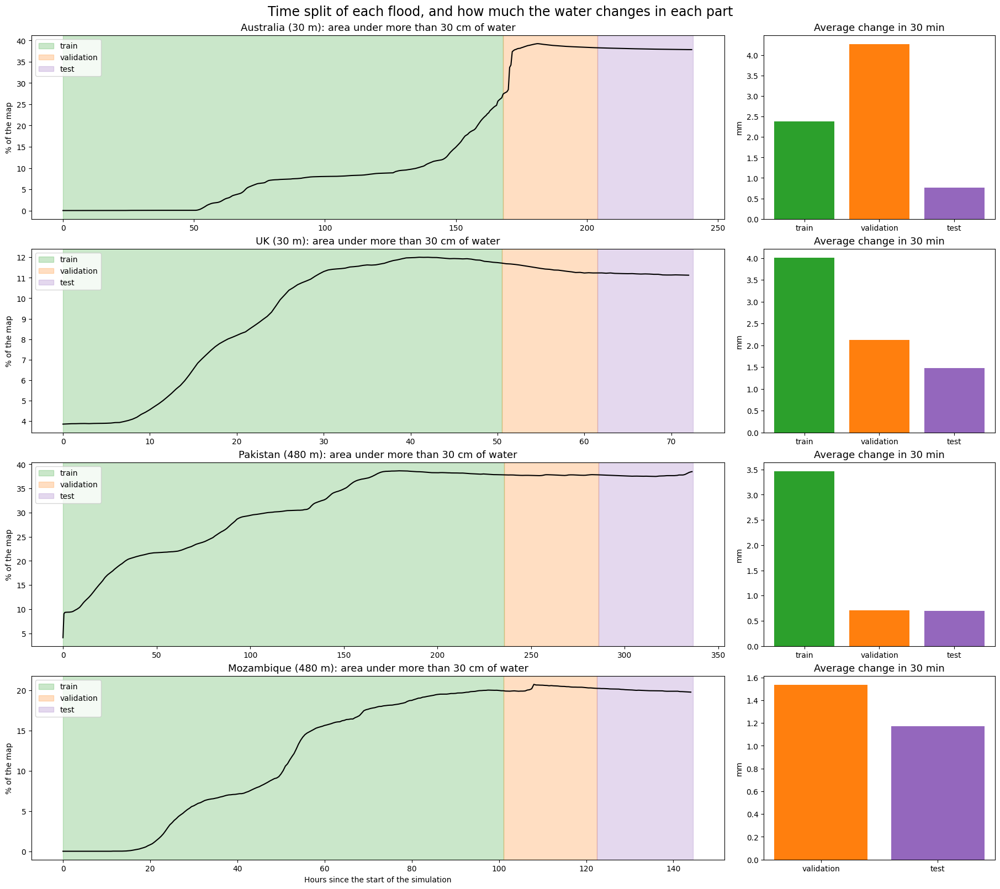

,Region,Part,Average change in 30 min (mm)
0,Australia (30 m),train,2.38
1,Australia (30 m),validation,4.27
2,Australia (30 m),test,0.76
3,UK (30 m),train,4.01
4,UK (30 m),validation,2.12
5,UK (30 m),test,1.47
6,Pakistan (480 m),train,3.47
7,Pakistan (480 m),validation,0.71
8,Pakistan (480 m),test,0.69
9,Mozambique (480 m),train,NaN


Saved table: 11_change_per_part.csv


In [ ]:
PART_COLOURS = {"train": "tab:green", "validation": "tab:orange", "test": "tab:purple"}

fig, axes = plt.subplots(4, 2, figsize=(18, 16), layout="constrained", gridspec_kw={"width_ratios": [3, 1]})
fig.suptitle("Time split of each flood, and how much the water changes in each part", fontsize=17)

change_rows = []

for row, (dataset, title) in enumerate(MAIN_DATASETS.items()):
    depth = data[dataset]["depth"]
    t = timeline[dataset]

    # Left: the flooded area over time, with the three parts shaded
    axes[row, 0].plot(t["hours"], 100 * t["flooded_share"], color="black", linewidth=1.5)

    for part, (start, end) in splits[dataset].items():
        axes[row, 0].axvspan(start * STEP_HOURS, end * STEP_HOURS, color=PART_COLOURS[part], alpha=0.25, label=part)

    axes[row, 0].set_title(title + ": area under more than 30 cm of water", fontsize=13)
    axes[row, 0].set_ylabel("% of the map")
    axes[row, 0].legend(loc="upper left")

    # Right: average change of the water depth in 30 minutes, in each part (wet cells only)
    part_changes = []

    for part, (start, end) in splits[dataset].items():
        changes = []

        for step in range(start, end - 1):
            now = depth[step]
            later = depth[step + 1]
            wet = (now > WET_DEPTH_M) | (later > WET_DEPTH_M)
            changes.append(np.mean(np.abs(later[wet] - now[wet])))

        average_change_mm = 1000 * float(np.mean(changes))
        part_changes.append(average_change_mm)
        change_rows.append({"Region": title, "Part": part, "Average change in 30 min (mm)": round(average_change_mm, 2)})

    axes[row, 1].bar(list(splits[dataset].keys()), part_changes, color=list(PART_COLOURS.values()))
    axes[row, 1].set_title("Average change in 30 min", fontsize=13)
    axes[row, 1].set_ylabel("mm")

axes[3, 0].set_xlabel("Hours since the start of the simulation")

save_figure(fig, "11_time_split")
plt.show()

change_table = pd.DataFrame(change_rows)
display(change_table)
save_table(change_table, "11_change_per_part")

### 5c. Normalisation values
Neural networks train best when every input has a similar range, so each input is later rescaled as
**(value − average) / spread**. The averages and spreads come from the **training part only**,
so nothing from the validation or test period leaks into training.
Ground height is rescaled per map, because absolute heights differ hugely between regions.

In [ ]:
normalisation = {}
normalisation_rows = []

for dataset, title in MAIN_DATASETS.items():
    depth = data[dataset]["depth"]
    rain = data[dataset]["rain"]
    start, end = splits[dataset]["train"]

    # Every 5th training map is enough to measure the average and the spread
    steps = np.arange(start, end - 1, 5)

    depth_sample = depth[steps]
    change_sample = depth[steps + 1] - depth[steps]
    rain_sample = rain[steps].astype("float32")
    terrain = data[dataset]["terrain"]

    samples = {
        "depth (m)": depth_sample,
        "change in 30 min (m)": change_sample,
        "rain (mm per hour)": rain_sample,
        "ground height (m)": terrain,
    }

    normalisation[dataset] = {}

    for name, values in samples.items():
        average = float(np.mean(values))
        spread = float(np.std(values))

        normalisation[dataset][name] = {"average": average, "spread": spread}
        normalisation_rows.append({"Region": title, "Input": name,
                                   "Average": round(average, 4), "Spread": round(spread, 4)})

with open(os.path.join(MODEL_INPUT_DIR, "normalisation.json"), "w") as file:
    json.dump(normalisation, file, indent=2)

normalisation_table = pd.DataFrame(normalisation_rows)
display(normalisation_table)
save_table(normalisation_table, "12_normalisation")

,Region,Input,Average,Spread
0,Australia (30 m),depth (m),0.0675,0.2234
1,Australia (30 m),change in 30 min (m),0.0008,0.0042
2,Australia (30 m),rain (mm per hour),1.6287,2.9675
3,Australia (30 m),ground height (m),22.0187,39.5297
4,UK (30 m),depth (m),0.0942,0.3201
5,UK (30 m),change in 30 min (m),0.0009,0.0058
6,UK (30 m),rain (mm per hour),1.9477,1.7609
7,UK (30 m),ground height (m),21.7935,7.9168
8,Pakistan (480 m),depth (m),0.3257,0.6540
9,Pakistan (480 m),change in 30 min (m),0.0008,0.0390


Saved table: 12_normalisation.csv


### 5d. One training example
One 128 x 128 tile of the Australian flood: the model gets the last **2 hours** (4 maps), the rain that has
**already fallen**, and the ground; it must predict the next **2 hours** (4 maps).
The bottom row is the part that is actually hard: the **change** from the current map.

Saved figure: 13_training_example.png


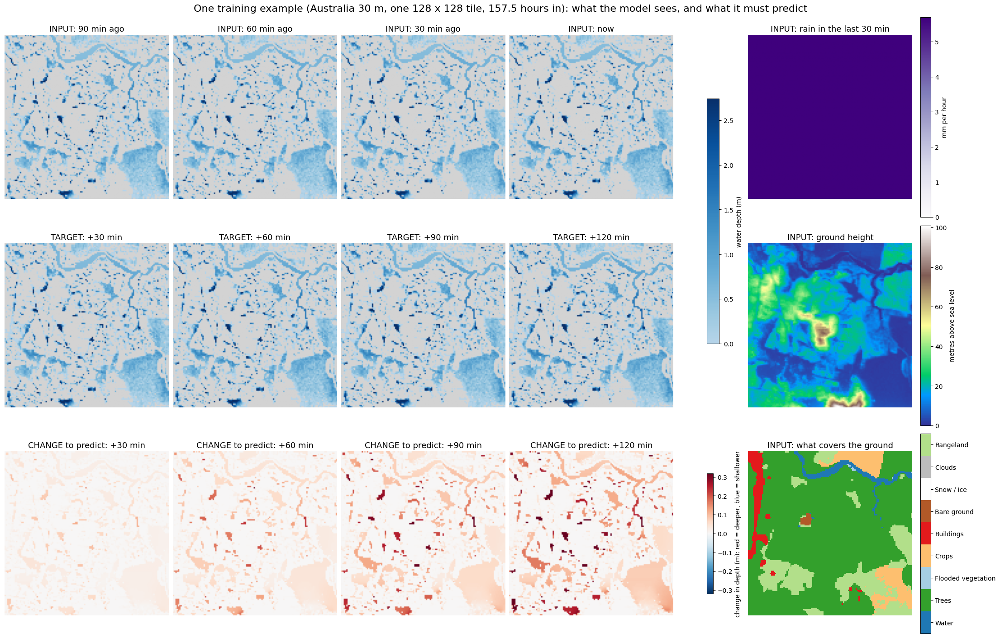

In [ ]:
example_dataset = "Australia_30m"
depth = data[example_dataset]["depth"]
rain = data[example_dataset]["rain"]
start, end = splits[example_dataset]["train"]

# Pick the moment in the training part where the average depth changes most over the next 2 hours
first_possible = start + INPUT_STEPS - 1
last_possible = end - OUTPUT_STEPS - 1
average_depth = timeline[example_dataset]["average_depth"]
future_change = [abs(average_depth[t + OUTPUT_STEPS] - average_depth[t]) for t in range(first_possible, last_possible + 1)]
now = first_possible + int(np.argmax(future_change))

# Pick the tile where the water changes most over those 2 hours
tiles = cut_into_tiles(depth.shape[1], depth.shape[2])
tile_changes = []

for top, left, height, width in tiles:
    change = depth[now + OUTPUT_STEPS, top:top + height, left:left + width] - depth[now, top:top + height, left:left + width]
    tile_changes.append(np.mean(np.abs(change)))

top, left, height, width = tiles[int(np.argmax(tile_changes))]


def tile_of(array_map):
    """Cuts the chosen tile out of a full map."""
    return np.array(array_map[top:top + height, left:left + width], dtype="float32")


# Same colour scale for all depth pictures
all_depths = np.stack([tile_of(depth[now + k]) for k in range(-INPUT_STEPS + 1, OUTPUT_STEPS + 1)])
top_value = np.percentile(all_depths[all_depths > WET_DEPTH_M], 98)

fig, axes = plt.subplots(3, 5, figsize=(22, 14), layout="constrained")
fig.suptitle("One training example (Australia 30 m, one 128 x 128 tile, " + str(now * STEP_HOURS) +
             " hours in): what the model sees, and what it must predict", fontsize=16)

# Row 1: the 4 input maps, and the rain that fell in the last half hour
for column in range(INPUT_STEPS):
    steps_back = INPUT_STEPS - 1 - column
    picture = show_water(axes[0, column], tile_of(depth[now - steps_back]), top_value)

    if steps_back == 0:
        axes[0, column].set_title("INPUT: now", fontsize=13)
    else:
        axes[0, column].set_title("INPUT: " + str(steps_back * 30) + " min ago", fontsize=13)

fig.colorbar(picture, ax=axes[0:2, 0:4], label="water depth (m)", shrink=0.6)

picture = axes[0, 4].imshow(tile_of(rain[now - 1]), cmap="Purples", vmin=0)
axes[0, 4].set_title("INPUT: rain in the last 30 min", fontsize=13)
fig.colorbar(picture, ax=axes[0, 4], label="mm per hour")

# Row 2: the 4 maps to predict, and the ground height
for column in range(OUTPUT_STEPS):
    minutes_ahead = (column + 1) * 30
    show_water(axes[1, column], tile_of(depth[now + column + 1]), top_value)
    axes[1, column].set_title("TARGET: +" + str(minutes_ahead) + " min", fontsize=13)

picture = axes[1, 4].imshow(tile_of(data[example_dataset]["terrain"]), cmap="terrain")
axes[1, 4].set_title("INPUT: ground height", fontsize=13)
fig.colorbar(picture, ax=axes[1, 4], label="metres above sea level")

# Row 3: how much each target differs from the current map (red = deeper, blue = shallower)
changes = [tile_of(depth[now + column + 1]) - tile_of(depth[now]) for column in range(OUTPUT_STEPS)]
largest_change = max(np.percentile(np.abs(c), 99) for c in changes)

for column in range(OUTPUT_STEPS):
    minutes_ahead = (column + 1) * 30
    picture = axes[2, column].imshow(changes[column], cmap="RdBu_r", vmin=-largest_change, vmax=largest_change)
    axes[2, column].set_title("CHANGE to predict: +" + str(minutes_ahead) + " min", fontsize=13)

fig.colorbar(picture, ax=axes[2, 0:4], label="change in depth (m): red = deeper, blue = shallower", shrink=0.6)

picture = axes[2, 4].imshow(land_cover_positions(tile_of(data[example_dataset]["land_cover"])),
                            cmap=land_cover_colours, vmin=-0.5, vmax=len(LAND_COVER) - 0.5, interpolation="nearest")
axes[2, 4].set_title("INPUT: what covers the ground", fontsize=13)
colour_bar = fig.colorbar(picture, ax=axes[2, 4], ticks=range(len(LAND_COVER)))
colour_bar.ax.set_yticklabels(land_cover_names)

for ax in axes.flat:
    ax.axis("off")

save_figure(fig, "13_training_example")
plt.show()

## 6. Summary and next steps
**Done so far**
- All four regions (six datasets) downloaded, checked for missing or impossible values, and pre-processed onto one grid per dataset
- Layer alignment checked with two independent tests (rivers and valleys)
- Rain timing checked: each rain file holds the rain of the **next** 30 minutes, so the model only receives rain that has already fallen
- Water balance checked against physics (section 4a)
- New severity label, time split and normalisation values saved for the model

**Next: the model**
- **CNN + ConvLSTM**: the CNN reads the spatial pattern of each map, the ConvLSTM carries the flood's history from map to map
- Two versions: forecasts for **128 x 128 tiles**, and forecasts for **whole maps**
- Forecasts **step by step**: each 30-minute prediction is fed back in to reach several hours ahead
- **Capsule network** head for the severity label from section 5a
- **Grad-CAM** heatmaps to show which areas drive each forecast
- A **NeuroSymbolic** rule layer on top of the network's output

In [ ]:
# Everything this notebook saved on Google Drive
for folder in [FIGURE_DIR, TABLE_DIR, MODEL_INPUT_DIR]:
    print(folder)

    for file_name in sorted(os.listdir(folder)):
        print("    ", file_name)

/content/drive/MyDrive/Flood_project/lab_outputs/figures
     02_preprocessing_demo_UK.png
     03_four_floods_overview.png
     04_flood_development.png
     05_rain_and_flooded_area.png
     06_water_balance.png
     07_depth_distribution.png
     08_persistence_error.png
     09_severity_new_label.png
     10_severity_old_vs_new.png
     11_time_split.png
     13_training_example.png
/content/drive/MyDrive/Flood_project/lab_outputs/tables
     01_dataset_overview.csv
     06_water_balance.csv
     08_persistence_error.csv
     10_severity_classes.csv
     11_change_per_part.csv
     12_normalisation.csv
/content/drive/MyDrive/Flood_project/model_inputs
     normalisation.json
     severity_Australia_30m.npz
     severity_Mozambique_480m.npz
     severity_Pakistan_480m.npz
     severity_UK_30m.npz
     time_splits.json
